## Regularisation
    Ridge - Apply penalty on square of coefficients
    Lasso - Apply penalty on Abosulte value of coefficients
    Elastic Net(Ridge and Lasso) - Combination of Ridge and Lasso
    Dropout - Drop some features randomly and train the model

In [ ]:
from warnings import filterwarnings
filterwarnings('ignore')

In [ ]:
import pandas as pd

url = (
    "https://raw.githubusercontent.com/Sindhura-tr/Datasets/refs/heads/main/Cars93.csv"
)
df = pd.read_csv(url, na_values=["", "NA"], keep_default_na=False)
df.head()

In [ ]:
df.info()

In [ ]:
s = df.isna().sum()
s[s > 0]

In [ ]:
df.duplicated().sum()

## Separate X and Y features

In [ ]:
X = df.drop(columns=["id", "Weight"])
Y = df[["Weight"]]

In [ ]:
cat = list(X.columns[X.dtypes == "object"])
con = list(X.columns[X.dtypes != "object"])

In [ ]:
cat

In [ ]:
con

## Feature Engineering: Data preprocessing and Data cleaning

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [ ]:
num_pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())

In [ ]:
cat_pipe = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=False),
)

In [ ]:
pre = ColumnTransformer([("con", num_pipe, con), ("cat", cat_pipe, cat)]).set_output(
    transform="pandas"
)

In [ ]:
pre

In [ ]:
X_pre = pre.fit_transform(X)
X_pre.head()

## Split the data into training and testing

In [ ]:
from sklearn.model_selection import train_test_split

xtrain, xtest, ytrain, ytest = train_test_split(
    X_pre, Y, train_size=0.75, random_state=42
)

In [ ]:
xtrain.head()

In [ ]:
xtest.head()

In [ ]:
ytrain.head()

In [ ]:
ytest.head()

## 1. Build Ridge model

In [ ]:
from sklearn.linear_model import Ridge, Lasso

In [ ]:
base_model = Ridge(alpha=1)
base_model.fit(xtrain, ytrain)

## Evaluation

In [ ]:
base_model.score(xtrain, ytrain)

In [ ]:
base_model.score(xtest, ytest)

## Hyperparameter tuning

In [ ]:
import numpy as np

params = {"alpha": np.arange(start=0.1, stop=100, step=0.1)}
params

## Gridsearch CV
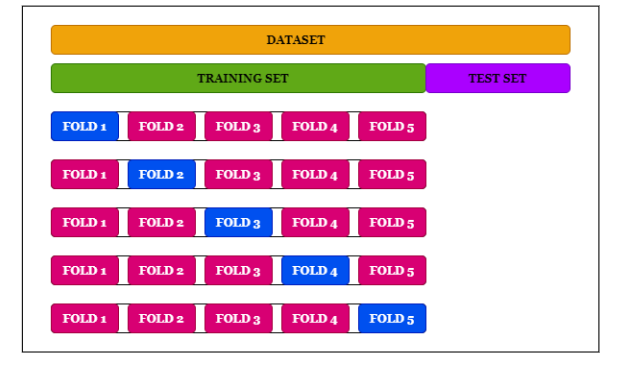

In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
model1 = Ridge()
gscv = GridSearchCV(estimator=model1, param_grid=params, cv=5, scoring="r2")
gscv.fit(xtrain, ytrain)

In [ ]:
gscv.scoring

In [ ]:
gscv.best_params_

In [ ]:
gscv.best_score_

In [ ]:
best_ridge = gscv.best_estimator_

In [ ]:
best_ridge.fit(xtrain, ytrain)

In [ ]:
best_ridge.score(xtrain, ytrain)

In [ ]:
best_ridge.score(xtest, ytest)

In [ ]:
from sklearn.model_selection import cross_val_score

In [ ]:
scores = cross_val_score(best_ridge, xtrain, ytrain, cv=5, scoring="r2")

In [ ]:
scores

In [ ]:
score = scores.mean()
score

In [ ]:
base_model2 = Lasso(alpha=1)

In [ ]:
base_model2.fit(xtrain, ytrain)

In [ ]:
base_model2.score(xtrain, ytrain)

In [ ]:
base_model2.score(xtest, ytest)

In [ ]:
model2 = Lasso()
gscv2 = GridSearchCV(estimator=model2, param_grid=params, scoring="r2", cv=5)

In [ ]:
gscv2.fit(xtrain, ytrain)

In [ ]:
gscv2.best_params_

In [ ]:
gscv2.best_score_

## Ridge model perform better than Lasso model with testing score 97%. Let's consider ridge model for final predictions

In [ ]:
url2 = "https://raw.githubusercontent.com/Sindhura-tr/Datasets/refs/heads/main/sample_cars93.csv"
xnew = pd.read_csv(url2, na_values=["", "NA"], keep_default_na=False)

In [ ]:
xnew.head()

In [ ]:
xnew_pre = pre.transform(xnew)
xnew_pre.head()

In [ ]:
weights_predicted = best_ridge.predict(xnew_pre)
weights_predicted = weights_predicted.round(2)
weights_predicted

In [ ]:
xnew["Weights Predicted"] = weights_predicted

In [ ]:
xnew.head()

In [ ]:
xnew.to_csv("Ridge_Weight Predicted Results.csv", index=False)